In [1]:
# This is the python script performing the analysis of many LC-MS files for RiPP modifications
import pandas as pd
import pickle
from pathlib import Path
from classes_spectrometry import AnalysisResults
from plotting_analysis_functions import *
import re

In [2]:
def build_analysis_objects(reports_path: str, overwrite: bool = False):
    """
    Scans the output directory for CURATED_APPROVED pkl files,
    reconstructs AnalysisResults objects, and saves them as per-experiment pkls.
    """
    reports_root = Path(reports_path)

    # Locate all curated output files
    curated_files = list(reports_root.rglob("*_CURATED_APPROVED.pkl"))
    print(f"Found {len(curated_files)} curated report files.")

    for file_path in curated_files:
        # Define where the object will be saved
        save_path = file_path.parent / f"{file_path.stem.replace('_CURATED_APPROVED', '')}_analysis_obj.pkl"

        if save_path.exists() and not overwrite:
            print(f"  Skipping: {save_path.name} (already exists)")
            continue

        try:
            # 1. Load the data frame (This contains your curated peak objects)
            with open(file_path, 'rb') as f:
                df = pickle.load(f)

            # 2. Extract unique experiments from the df
            # (Assuming you have an 'experiment_id' or 'group_name' column)
            group_name = file_path.stem.split('_CURATED')[0]

            # 3. Reconstruct the AnalysisResults object
            # Note: This assumes you have the raw 'experiment' object available
            # or stored. If not, you might need to re-load it from your pickle-cache.
            # Here we assume a logic that pulls the experiment from a known path
            experiment_pkl = file_path.parent / f"{group_name}_experiment.pkl"
            with open(experiment_pkl, 'rb') as f:
                exp = pickle.load(f)

            results = AnalysisResults(exp)

            # 4. Populate results with peaks from the dataframe
            # Map the rows from your 'CURATED_APPROVED' df back to peak objects
            for _, row in df.iterrows():
                target = row['target_object']
                peak = row['peak_object']
                results.add_peaks(target, [peak])

            # 5. Save the AnalysisResults container
            with open(save_path, 'wb') as f:
                pickle.dump(results, f)
            print(f"  Successfully built and saved: {save_path.name}")

        except Exception as e:
            print(f"  ERROR processing {file_path.name}: {e}")

def create_master_plotting_df(reports_path: str, meta_excel_path: str) -> pd.DataFrame:
    """
    Directly aggregates all curated long-form DataFrames from your report folders
    and safely joins them with your plate metadata.
    """
    import pandas as pd
    import pickle
    from pathlib import Path

    reports_root = Path(reports_path)

    # 1. Load plate metadata from the input Excel file
    print(f"📖 Loading metadata from: {meta_excel_path}")
    meta_df = pd.read_excel(meta_excel_path)

    # 2. Locate all curated approved data files (checking both pkl and xlsx format)
    curated_files = list(reports_root.rglob("*_CURATED_APPROVED.pkl"))
    if not curated_files:
        curated_files = list(reports_root.rglob("*_CURATED_APPROVED.xlsx"))

    print(f"🔍 Found {len(curated_files)} curated report files to aggregate.")

    df_list = []
    for file_path in curated_files:
        try:
            if file_path.suffix == '.pkl':
                df_chunk = pd.read_pickle(file_path)
            else:
                df_chunk = pd.read_excel(file_path)

            if df_chunk.empty:
                continue

            # Record provenance so rows can be traced back to the original curated file
            df_chunk['_source_file'] = file_path.name
            df_list.append(df_chunk)
        except Exception as e:
            print(f"  ⚠️ Warning: Could not read {file_path.name}. Error: {e}")

    if not df_list:
        print("❌ CRITICAL ERROR: No data could be parsed from your curated files. Check your folder paths.")
        return pd.DataFrame()

    # 3. Concatenate all individual files into one master data structure
    master_df = pd.concat(df_list, ignore_index=True)

    # 4. Standardize column names to maintain 100% compatibility with your plotting functions
    # (e.g., mapping 'peak_area' -> 'area', 'rt_consensus' -> 'rt')
    column_mappings = {
        'peak_area': 'area',
        'rt_consensus': 'rt',
        'target_sequence': 'peptide_sequence',
        'target_modifications': 'modification_state'
    }
    for old_col, new_col in column_mappings.items():
        if old_col in master_df.columns and new_col not in master_df.columns:
            master_df[new_col] = master_df[old_col]

    # 5. Structural Validation Checks
    print(f"📋 Master DF Columns: {list(master_df.columns)}")
    print(f"📋 Metadata DF Columns: {list(meta_df.columns)}")

    if 'sample_id' not in master_df.columns:
        print("❌ ERROR: 'sample_id' missing from your curated data. Cannot execute merge.")
        return master_df

    if 'sample_id' not in meta_df.columns:
        print("❌ ERROR: 'sample_id' column missing from your metadata Excel sheet.")
        return master_df

    # 6. Execute Left Merge to append plate metadata context
    # Use an indicator column and suffixes so the origin of each merged field is clear
    final_df = master_df.merge(meta_df, on=['sample_id', 'experiment_id'], how='left',
                               indicator='merge_source', suffixes=('', '_meta'))

    # Report merge stats to help backtracking rows that didn't find metadata
    merge_counts = final_df['merge_source'].value_counts().to_dict()
    print(f"🔗 Merge outcome counts: {merge_counts}")
    if merge_counts.get('left_only', 0) > 0:
        print(f"  ⚠️ {merge_counts.get('left_only', 0)} rows did not match any metadata row (left_only). Check 'sample_id' and 'experiment_id'.")
    # Print expanded diagnostics (if plotting_analysis_functions provides helper)
    try:
        print_merge_diagnostics(final_df, indicator_col='merge_source', n=8)
    except Exception:
        pass

    # 7. Save the master plotting database back to disk
    save_path = reports_root / "master_plotting_data.pkl"
    with open(save_path, 'wb') as f:
        pickle.dump(final_df, f)

    print(f"🎉 Success! Combined dataset contains {len(final_df)} rows. Saved to {save_path.name}")
    return final_df

# --- 1. Pre-flight Compatibility Formatting ---

def prepare_dataframe_for_plotting(df: pd.DataFrame) -> pd.DataFrame:
    """
    Guarantees that columns and categorical fields perfectly match the exact
    expectations of your custom calculation and alignment plotting functions.
    """
    plot_df = df.copy()

    # 1. Map alternative column names to match your strict function expectations
    column_mappings = {
        'group_name': 'experiment_id',       # Maps group_name to experiment_id
        'peak_area': 'area',
        'target_sequence': 'peptide_sequence',
        'cluster_id': 'cut_id'
    }

    for old_col, new_col in column_mappings.items():
        if old_col in plot_df.columns and new_col not in plot_df.columns:
            plot_df[new_col] = plot_df[old_col]

    # Ensure 'target_sequence' exists (keep a copy of the unmodified peptide string)
    if 'target_sequence' not in plot_df.columns and 'peptide_sequence' in plot_df.columns:
        plot_df['target_sequence'] = plot_df['peptide_sequence']

    # 2. Since this data is already CURATED_APPROVED, treat everything as accepted 'Gold'
    # if the 'tier' column isn't explicitly present.
    if 'tier' not in plot_df.columns:
        plot_df['tier'] = 'Gold'

    # 3. Handle modification string conversions expected by your calculator loop
    if 'target_modifications' in plot_df.columns:
        # Standardize string format to look like your check: "{'unmodified': None}"
        plot_df['modification_state'] = plot_df['target_modifications'].astype(str).replace({
            "{'unmodified': None}": "{'unmodified': None}",
            "unmodified": "{'unmodified': None}"
        })
    elif 'modification_state' not in plot_df.columns:
        plot_df['modification_state'] = "{'unmodified': None}"

    # 4. Final safety fallbacks for columns that absolutely must exist
    required_cols = ['experiment_id', 'sample_id', 'peptide_sequence', 'cut_id', 'enzyme', 'precursor_name', 'area']
    for col in required_cols:
        if col not in plot_df.columns:
            plot_df[col] = 'N/A' if col != 'area' else 0.0

    return plot_df


In [3]:
from pathlib import Path
from classes_spectrometry import AnalysisResults
# Import the functions we built: build_analysis_objects, create_master_plotting_df

# --- Configuration ---
ROOT_DIR = r'D:\Spliceotide_Data_Analysis\output_reports_plates'
META_EXCEL = r'D:\Spliceotide_Data_Analysis\input_excel_files\96_well_plate_expressions.xlsx'

def run_full_pipeline(root_dir, meta_file):
    print("🚀 Starting Full Analysis Pipeline...")

    # 1. Build Analysis Objects from your curated reports
    # This turns your '_CURATED_APPROVED.pkl' into '_analysis_obj.pkl'
    print("--- Step 1: Reconstructing Analysis Objects ---")
    build_analysis_objects(root_dir)

    # 2. Combine into a Master Plotting DataFrame
    # This aggregates all peaks across all samples into one clean table
    print("--- Step 2: Aggregating Data into Master DataFrame ---")
    master_df = create_master_plotting_df(root_dir, meta_file)

    print(f"✅ Pipeline Complete. Master DataFrame contains {len(master_df)} entries.")
    return master_df

# --- Main Execution ---
INPUT_EXCEL_FILE = r'D:\Spliceotide_Data_Analysis\input_excel_files\96_well_plate_expressions.xlsx'
REPORTS_PATH = r'D:\Spliceotide_Data_Analysis\output_reports_plates'

# Run the direct aggregation mapping pipeline
master_df = create_master_plotting_df(REPORTS_PATH, INPUT_EXCEL_FILE)

📖 Loading metadata from: D:\Spliceotide_Data_Analysis\input_excel_files\96_well_plate_expressions.xlsx
🔍 Found 139 curated report files to aggregate.
📋 Master DF Columns: ['experiment_id', 'group_name', 'sample_id', 'replicate_index', 'target_sequence', 'target_modifications', 'charge', 'cluster_id', 'rt_consensus', 'rt_start', 'rt_end', 'peak_area', 'ms2_matched', 'quality_score', 'decoy_unmatched', 'median_error_ppm', 'is_stub', 'peak_object', 'target_object', '_source_file', 'area', 'rt', 'peptide_sequence', 'modification_state']
📋 Metadata DF Columns: ['sample_id', 'date', 'experiment_id', 'instrument', 'program_name', 'host_species', 'host_strain', 'maturase_plasmid', 'maturase_name', 'maturase_induction', 'precursor_plasmid', 'precursor_name', 'precursor_induction', 'culture_medium', 'expression_temperature', 'expression_scale', 'expression_time', 'digestion', 'input_mzml_folder', 'input_mzml', 'output_folder_name', 'peptide_sequence', 'core_start', 'core_end', 'modified_sequence

In [4]:
# --- 2. Data Preparation Chain ---
# Step A: Standardize the master DataFrame columns
ready_master_df = prepare_dataframe_for_plotting(master_df)

# Step B: Run your custom ratio calculator (sums across charges, handles tiers)
processed_ratios_df = calculate_charges_mod_ratios(ready_master_df)

print(f"📊 Summary data ready. Calculated modification ratios for {len(processed_ratios_df)} features.")

📊 Summary data ready. Calculated modification ratios for 517 features.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


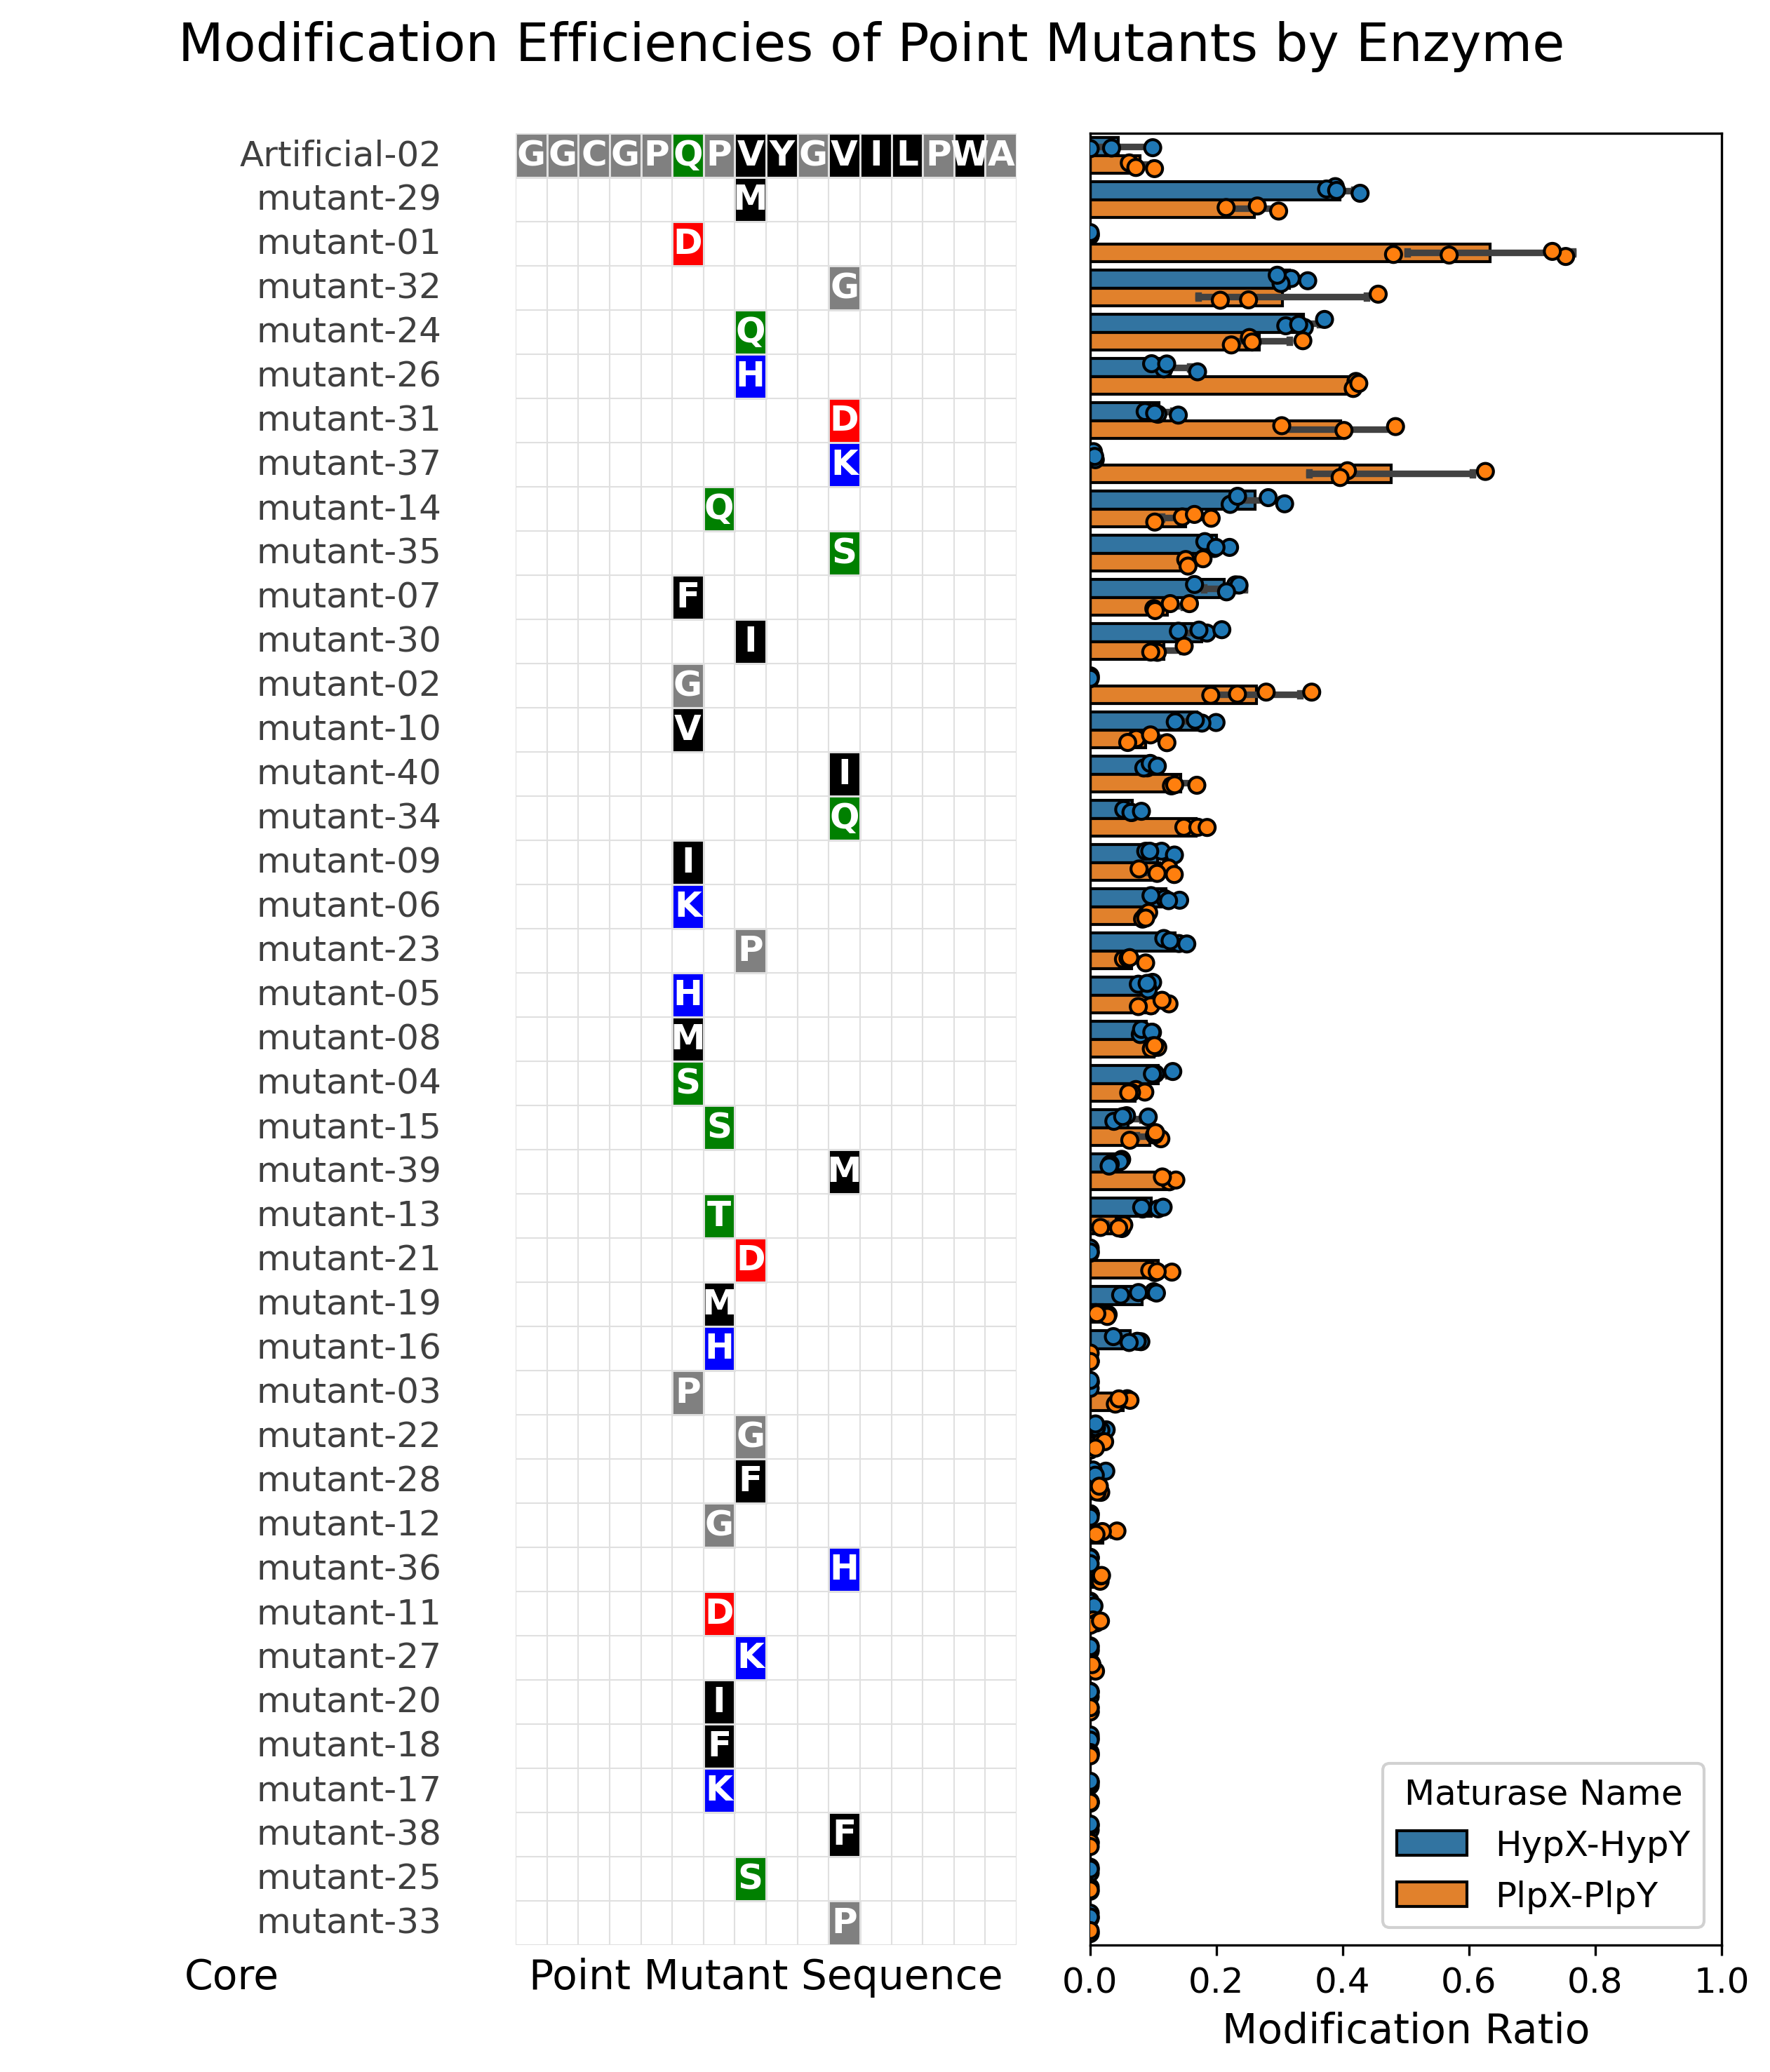

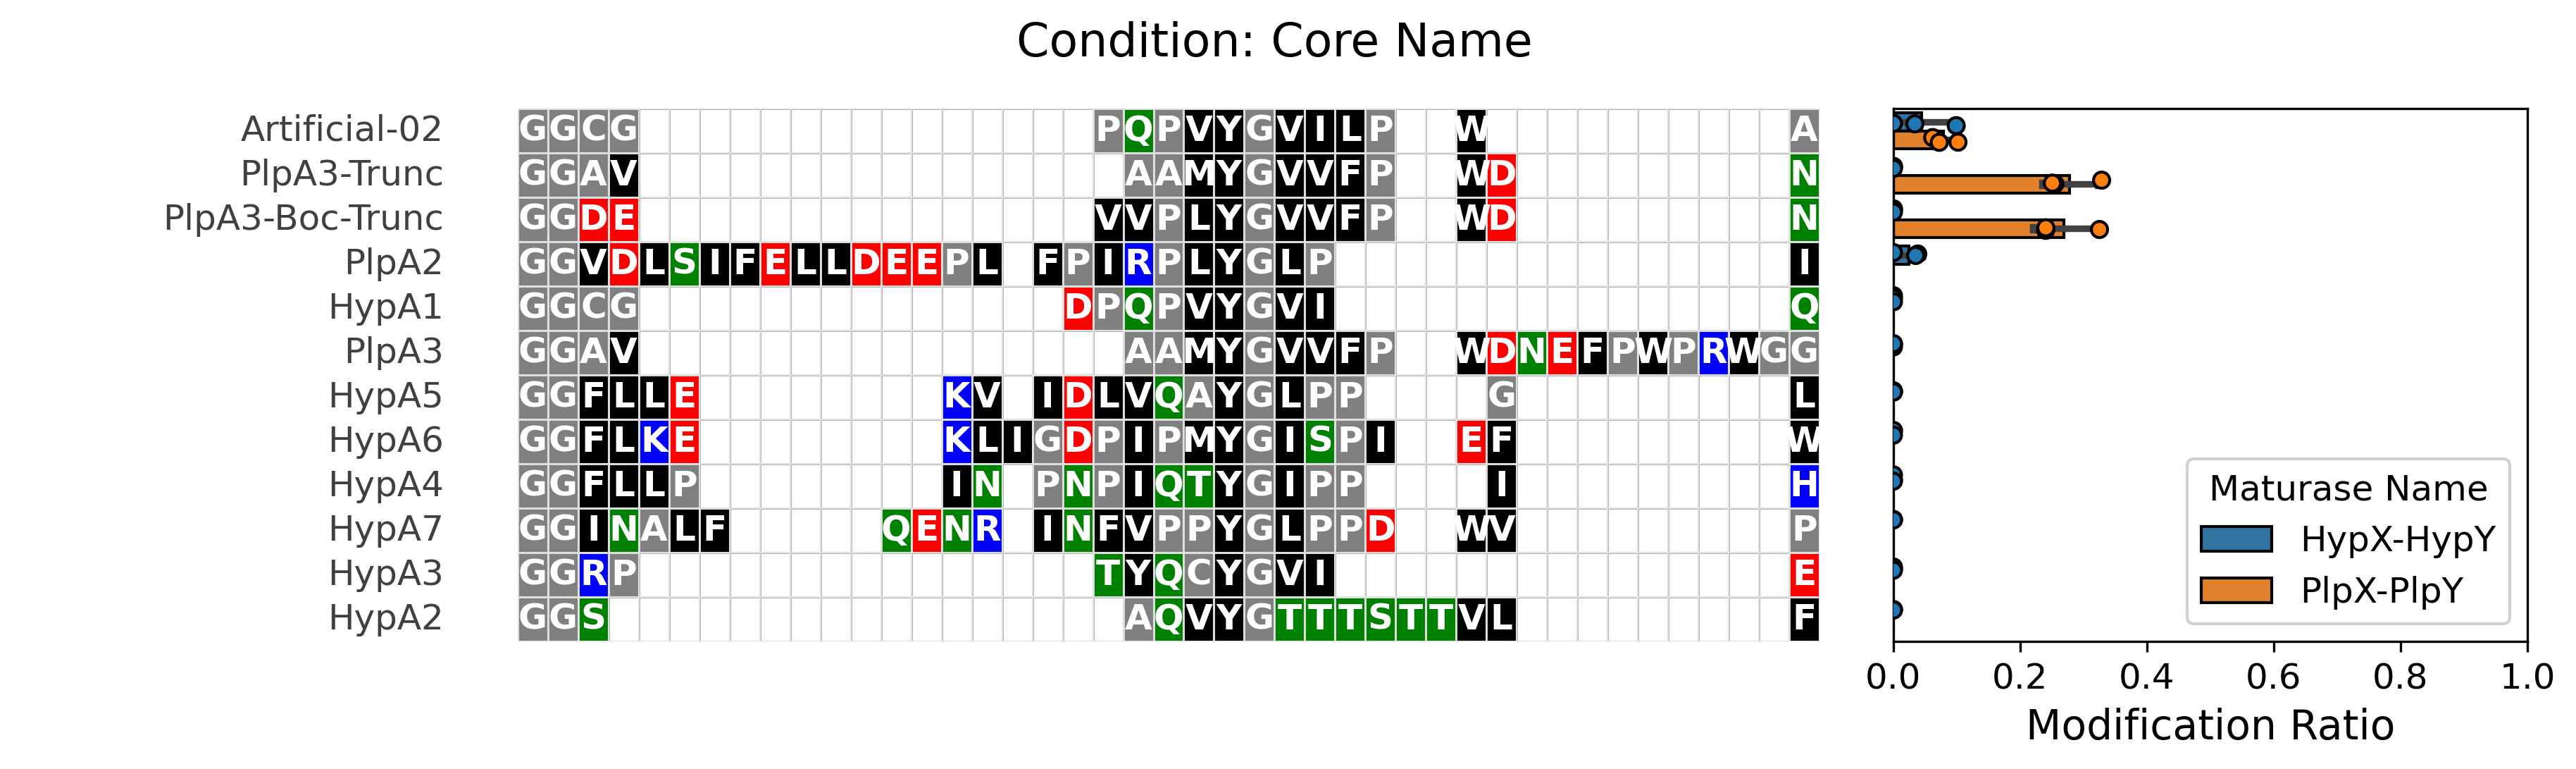

In [5]:
def split_core_name(x):
    if re.search("HypAc-TEV", x):
        core = x.split("HypAc-TEV-")[-1]
    elif re.search("HypA[1-9]-", x):
        core = x.split("HypA[1-9]-")[-1]
    elif re.search("PlpA3-TEV", x):
        core = x.split("PlpA3-TEV-")[-1]
    else:
        core = x
    return core
def two_digit_core(x):
    if re.search("[a-zA-Z]-[1-9]{1}$", x):
        core = x.split("-")[0] + "-0" + x.split("-")[-1]
    else:
        core = x
    return core
processed_ratios_df["full_core_sequence"] = processed_ratios_df.apply(
    lambda row: row["peptide_sequence_meta"][int(row["core_start"])-2:],
    axis=1)
# we make new column with the solubility tag
tag_names = ["Fh8-chaos", "Fh8",  "RSTN1", "Pfu-MBP", "sfGFP", "Fka-MTR"]
processed_ratios_df["solubility_tag"] = processed_ratios_df["precursor_name"].apply(
    lambda x: next((tag for tag in tag_names if tag in x), "None")
)
processed_ratios_df["core_name"] = processed_ratios_df["precursor_name"].apply(lambda x: split_core_name(x))
processed_ratios_df["core_name"] = processed_ratios_df["core_name"].apply(lambda x: two_digit_core(x))
processed_ratios_df["full_core_sequence"] = processed_ratios_df["full_core_sequence"].str.replace("*", "", regex=False)

# --- 3. Trigger Your Custom Alignments and Plots ---
# Define the wild-type reference sequence you are aligning your variants against
# (Change this string to match your exact sequence in the dataset)

point_mutant_comparison = processed_ratios_df[processed_ratios_df["experiment_id"] == "point_mutants"]


# we plot
point_mutant_plot = point_mutant_comparison[
    (point_mutant_comparison["precursor_name"].str.contains("mutant")) |
    (point_mutant_comparison["precursor_plasmid"] == "TJ-C-706") |
    (point_mutant_comparison["precursor_plasmid"] == "TJ-C-710")
]
REFERENCE_SEQUENCE = "GGCGPQPVYGVILPWA"
create_grouped_alignment_plot(
    point_mutant_plot,
    ref_sequence = REFERENCE_SEQUENCE,
    metadata_cols= ['core_name'],
    color_scheme_name= "hydrophobicity",
    show_ddg= False,
    preset = 'poster',
    use_alignment = True,
    drop_identical = True,
    sequence_column = "target_sequence",
    metatitle="Core",
    seqtitle="Point Mutant Sequence",
    suptitle="Modification Efficiencies of Point Mutants by Enzyme",
    savepath=r"summary_data_files/point_mutant_plates_plot.eps"
)

other_peptides = point_mutant_comparison[(point_mutant_comparison["precursor_name"].str.contains("mutant")) == False]
REFERENCE_SEQUENCE = "GGCGPQPVYGVILPWA"
create_grouped_alignment_plot(
    other_peptides,
    ref_sequence = REFERENCE_SEQUENCE,
    metadata_cols= ['core_name'],
    color_scheme_name= "hydrophobicity",
    show_ddg= False,
    preset = 'poster',
    savepath = None,
    use_alignment = True,
    drop_identical = False,
    sequence_column = "target_sequence")

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


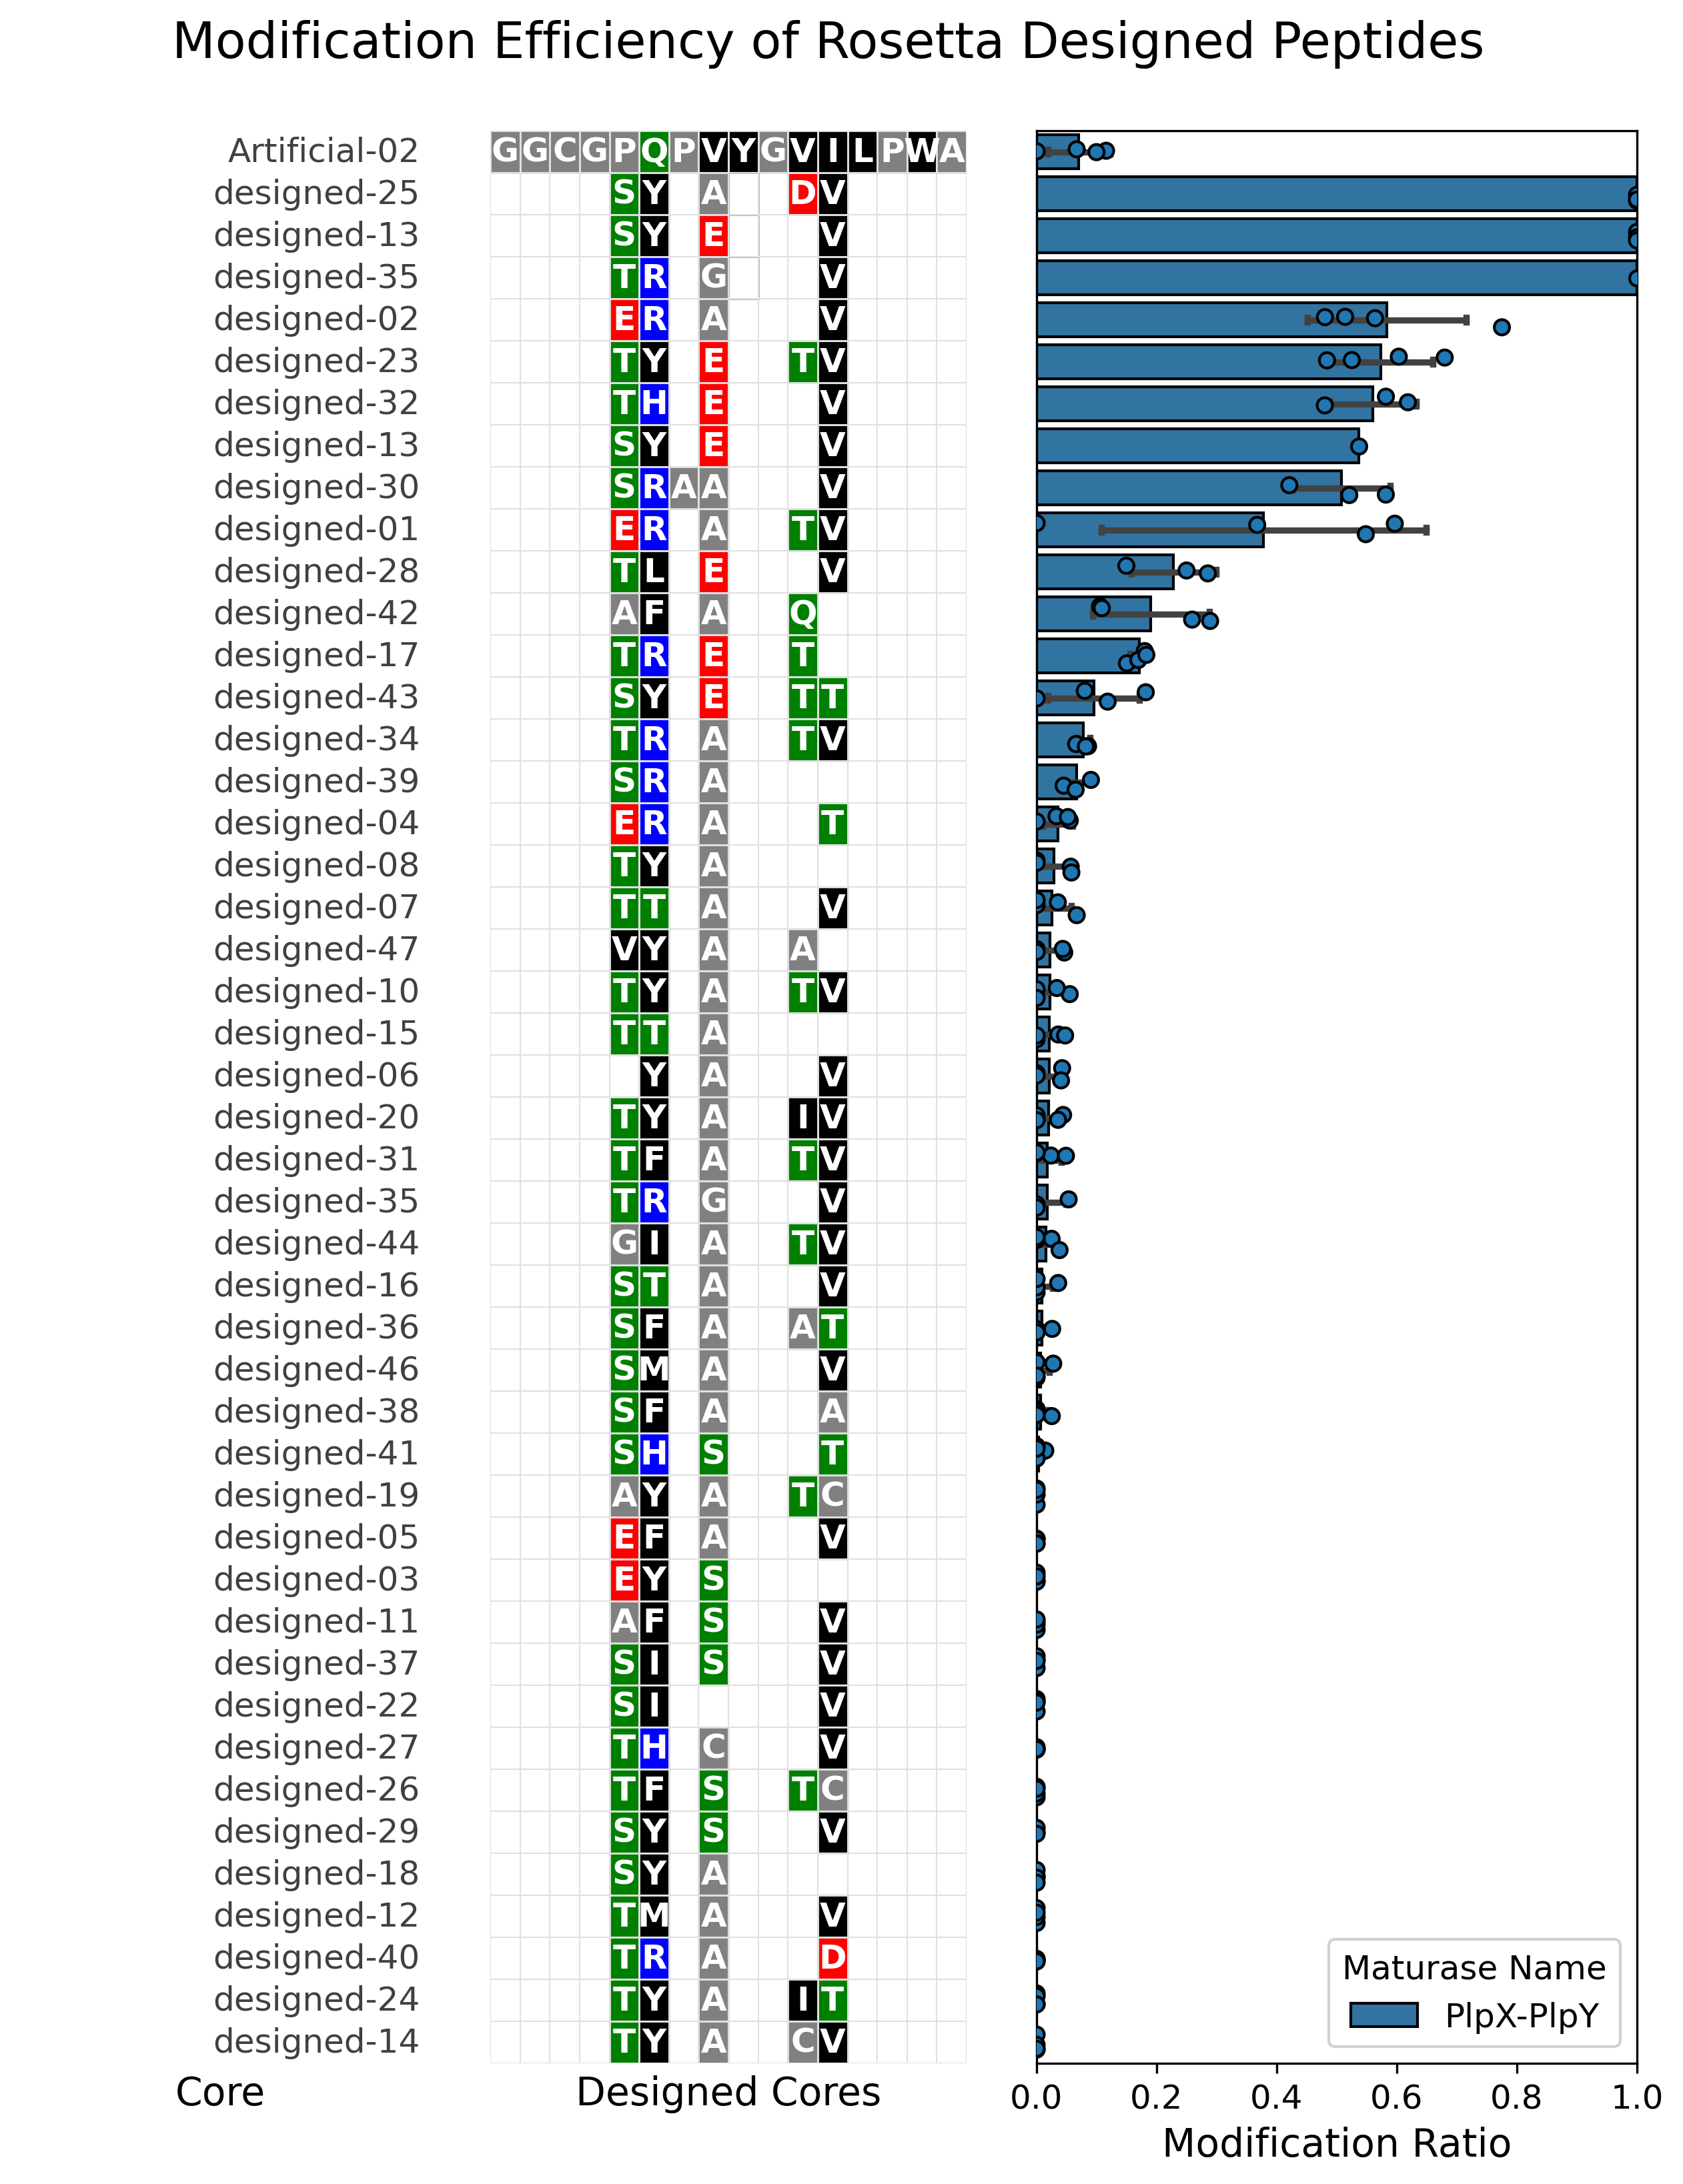

In [8]:

rosetta_comparison = processed_ratios_df[processed_ratios_df["experiment_id"] == "rosetta_top_47"]
# If your dataset spans multiple distinct enzymes (e.g., different maturities or conditions):
REFERENCE_SEQUENCE = "GGCGPQPVYGVILPWA"

REFERENCE_SEQUENCE = "GGCGPQPVYGVILPWA"
create_grouped_alignment_plot(
    rosetta_comparison,
    ref_sequence = REFERENCE_SEQUENCE,
    metadata_cols= ['core_name'],
    color_scheme_name= "hydrophobicity",
    show_ddg= False,
    preset = 'poster',
    use_alignment = True,
    drop_identical = True,
    sequence_column = "target_sequence",
    metatitle="Core",
    seqtitle="Designed Cores",
    suptitle="Modification Efficiency of Rosetta Designed Peptides",
    savepath=r"summary_data_files/rosetta_designs_plates_plot.eps"
)


In [7]:
# we save the processed ratios df to a excel file for further analysis inside the summary_data_files folder
processed_ratios_df.to_excel("summary_data_files/96_well_plates_processed_ratios_df.xlsx", index=False)
# we save the point_mutant_comparison df to a excel file for further analysis inside the summary_data_files folder
point_mutant_comparison.to_excel("summary_data_files/96_well_plates_point_mutant_comparison.xlsx", index=False)
# we save the rosetta_comparison df to a excel file for further analysis inside the summary_data_files folder
rosetta_comparison.to_excel("summary_data_files/96_well_plates_rosetta_comparison.xlsx", index=False)